# 15 — Decoder comparison

Collects `runs/notebooks/*.json`, written by `10`–`14` (run those first). All on DB5 exercise 1, 16 channels at
200 Hz, 200 ms windows every 50 ms, train on repetitions 1–4, test on 5–6.

- **balanced_accuracy** (mean recall over the 13 classes) is the main number: rest is ~60 % of the windows.
- **worst_user_balanced**: the weakest subject.
- **switches_per_s**: decision changes per second while one gesture is held (lower = steadier, before any smoothing).
- **latency_us**: one decision of the decoder (normalization + forward pass of one window, numpy). The features add
  ~65 µs per 50 ms step (hand-crafted) or less (RAW).

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt

from src import report

if Path.cwd().name == "notebooks":
    os.chdir("..")

In [2]:
summaries = report.load_all()
table = report.table(summaries)
table.round(3)

accuracy  balanced_accuracy  macro_f1  \
decoder   regime                                            
cnn       per_user     0.738              0.596     0.556   
          pooled       0.683              0.512     0.474   
          loso         0.623              0.376     0.359   
lda       per_user     0.810              0.643     0.653   
          pooled       0.730              0.461     0.467   
          loso         0.701              0.389     0.393   
lda_stack per_user     0.797              0.709     0.667   
          pooled       0.730              0.548     0.513   
          loso         0.658              0.366     0.348   
mlp       per_user     0.802              0.722     0.674   
          pooled       0.770              0.653     0.606   
          loso         0.616              0.357     0.334   
nn_lda    per_user     0.834              0.685     0.692   
          pooled       0.778              0.568     0.581   
          loso         0.692              0.364     0.378   

                    worst_user_balanced  switches_per_s  latency_us  \
decoder   regime                                                      
cnn       per_user                0.519           4.312     142.208   
          pooled                  0.387           5.097     142.208   
          loso                    0.251           5.648     142.208   
lda       per_user                0.566           2.468       7.375   
          pooled                  0.291           3.519       7.375   
          loso                    0.234           3.690       7.375   
lda_stack per_user                0.585           2.756      18.792   
          pooled                  0.435           4.378      18.792   
          loso                    0.228           4.738      18.792   
mlp       per_user                0.604           2.554      14.791   
          pooled                  0.532           3.923      14.791   
          loso                    0.241           5.448      14.791   
nn_lda    per_user                0.595           2.360      14.500   
          pooled                  0.374           3.490      14.500   
          loso                    0.228           4.430      14.500   

                    evaluation_s  
decoder   regime                  
cnn       per_user       109.417  
          pooled          30.703  
          loso           497.180  
lda       per_user         0.940  
          pooled           0.156  
          loso             1.876  
lda_stack per_user        21.196  
          pooled           9.827  
          loso           153.259  
mlp       per_user        42.887  
          pooled          20.397  
          loso           313.755  
nn_lda    per_user        33.819  
          pooled          18.931  
          loso           223.461

## Balanced accuracy per regime

regime,per_user,pooled,loso
decoder,,,
cnn,0.596,0.512,0.376
lda,0.643,0.461,0.389
lda_stack,0.709,0.548,0.366
mlp,0.722,0.653,0.357
nn_lda,0.685,0.568,0.364


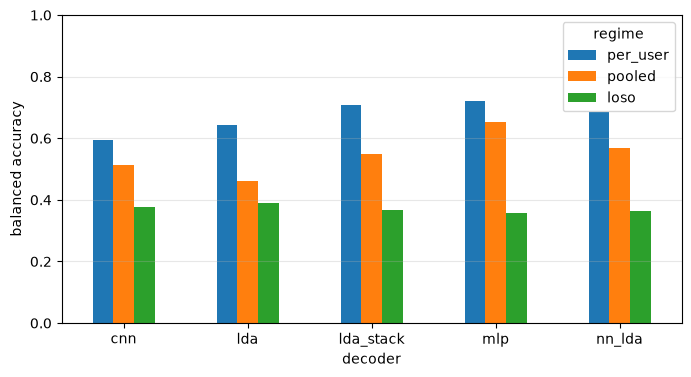

In [3]:
pivot = table["balanced_accuracy"].unstack("regime")[list(report.REGIMES)]
ax = pivot.plot.bar(figsize=(8, 4), rot=0, ylim=(0, 1), ylabel="balanced accuracy")
ax.grid(axis="y", alpha=0.3)
pivot.round(3)

## Accuracy vs inference cost

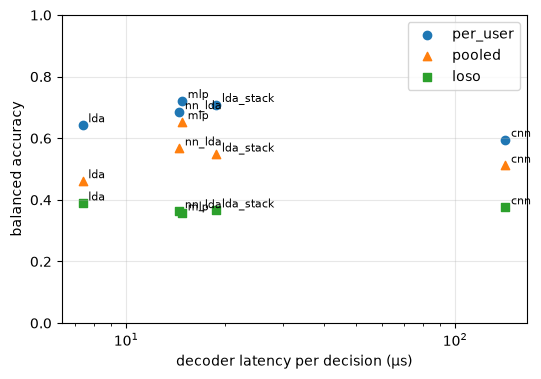

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
for regime, marker in zip(report.REGIMES, "o^s", strict=True):
    sub = table.xs(regime, level="regime")
    ax.scatter(sub["latency_us"], sub["balanced_accuracy"], marker=marker, label=regime)
    for name, row in sub.iterrows():
        ax.annotate(
            name, (row["latency_us"], row["balanced_accuracy"]), fontsize=8, xytext=(4, 2), textcoords="offset points"
        )
ax.set(xscale="log", xlabel="decoder latency per decision (µs)", ylabel="balanced accuracy", ylim=(0, 1))
ax.grid(alpha=0.3)
ax.legend()

## Calibration effort (leave one subject out, adapted with *n* seconds per class)

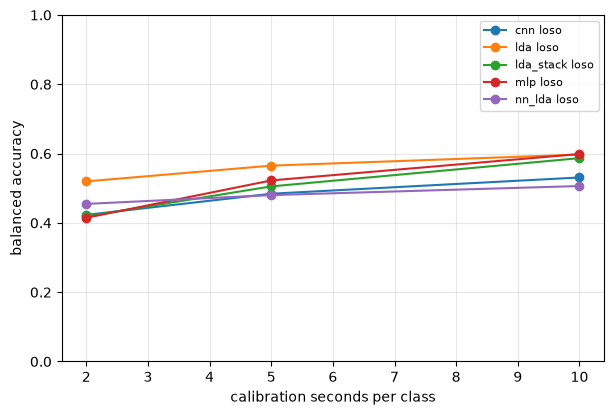

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
report.plot_calibration(ax, summaries, regimes=("loso",))